Hough lines in Sample1.png: 1054
LSD lines in Sample1.png: 1158


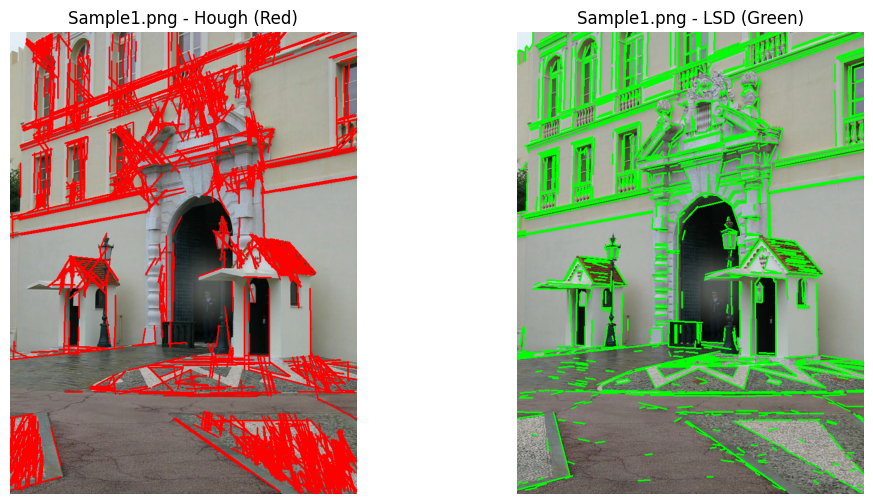

Hough lines in Sample2.png: 71
LSD lines in Sample2.png: 243


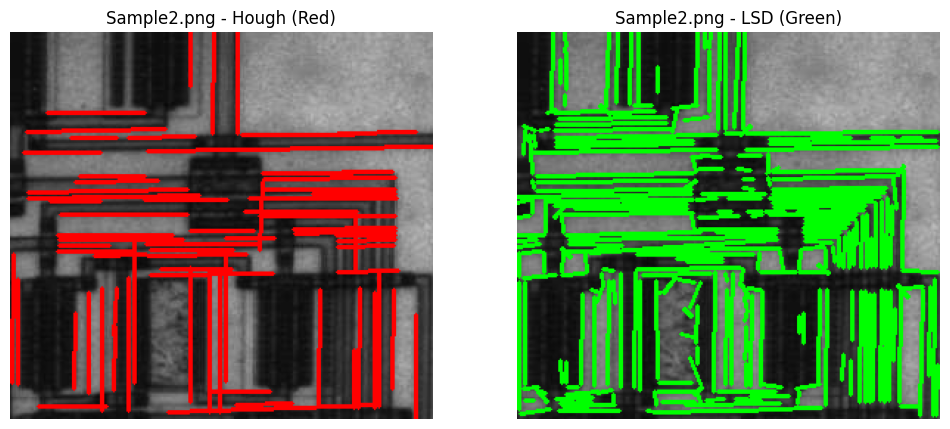

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

images = ["Sample1.png", "Sample2.png"]

for img_file in images:
    img = cv2.imread(img_file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (3, 3), 1.0)
    
    edges = cv2.Canny(blur, 50, 150, apertureSize=3)

    lines_hough = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=50, minLineLength=30, maxLineGap=10)
    
    hough_img = img.copy()
    if lines_hough is not None:
        for line in lines_hough:
            x1, y1, x2, y2 = line[0]
            cv2.line(hough_img, (x1, y1), (x2, y2), (0, 0, 255), 2)  # Red lines

    lsd = cv2.createLineSegmentDetector(0)
    lines_lsd, width, prec, nfa = lsd.detect(gray)
    
    lsd_img = img.copy()
    if lines_lsd is not None:
        for line in lines_lsd:
            x0, y0, x1, y1 = line[0]
            cv2.line(lsd_img, (int(x0), int(y0)), (int(x1), int(y1)), (0, 255, 0), 2)  # Green lines

    hough_count = 0 if lines_hough is None else len(lines_hough)
    lsd_count = 0 if lines_lsd is None else len(lines_lsd)

    print(f"Hough lines in {img_file}: {hough_count}")
    print(f"LSD lines in {img_file}: {lsd_count}")

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(hough_img, cv2.COLOR_BGR2RGB))
    plt.title(f"{img_file} - Hough (Red)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(lsd_img, cv2.COLOR_BGR2RGB))
    plt.title(f"{img_file} - LSD (Green)")
    plt.axis("off")

    plt.show()